In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)
import numpy as np

# X = GPA (Shape: 10 rows, 1 column)
x = np.array([8.97, 9.36, 7.78, 8.57, 6.26, 7.45, 6.59, 9.62, 7.82, 8.01])

# y = Package in LPA (Shape: 10 elements)
y = np.array([19.24, 18.02, 12.31, 14.92,  7.68, 
              10.98,  8.15, 21.43, 14.22, 13.57])

x,y

(array([8.97, 9.36, 7.78, 8.57, 6.26, 7.45, 6.59, 9.62, 7.82, 8.01]),
 array([19.24, 18.02, 12.31, 14.92,  7.68, 10.98,  8.15, 21.43, 14.22,
        13.57]))

In [3]:
nume=sum((x-x.mean())*(y-y.mean()))
den=sum((x-x.mean())**2)

m=nume/den
b=y.mean()-m*x.mean()
m,b

(3.9857199509730306, -18.00514556567608)

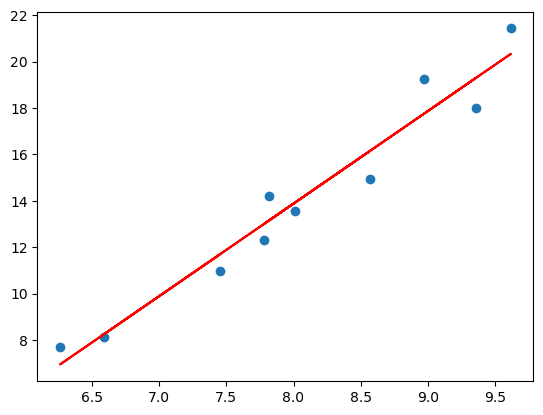

In [4]:
plt.scatter(x,y)
plt.plot(x,m*x+b,color='r')

In [5]:
from sklearn.linear_model import LinearRegression
model= LinearRegression()
model.fit(x.reshape(-1,1),y)

LinearRegression()

In [6]:
model.coef_,model.intercept_

(array([3.98571995]), -18.005145565676088)

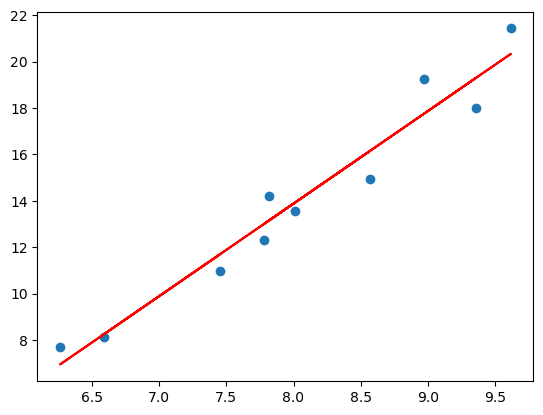

In [7]:
plt.scatter(x,y)
plt.plot(x,model.coef_*x+model.intercept_,color='r')

# Multiple Liner Regression

In [8]:
df=pd.read_csv(r'../../Datasets\Exp_Salaries.csv')
df.head()

,Salary,Years_Previous_Experience,Years Employed,Years_Education,Gender,Department,Number_Supervised
0,32782,1,0,7,Male,A,0
1,32920,3,15,9,Female,A,4
2,29548,6,5,1,Male,A,0
3,39828,6,18,5,Female,A,5
4,31528,11,3,3,Male,A,6


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46 entries, 0 to 45
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Salary                     46 non-null     int64 
 1   Years_Previous_Experience  46 non-null     int64 
 2   Years Employed             46 non-null     int64 
 3   Years_Education            46 non-null     int64 
 4   Gender                     46 non-null     object
 5   Department                 46 non-null     object
 6   Number_Supervised          46 non-null     int64 
dtypes: int64(5), object(2)
memory usage: 2.6+ KB


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_transformer,make_column_selector
from sklearn.metrics import r2_score
X,y=df.drop('Salary',axis=1), df['Salary']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3, random_state=26)

In [11]:
ohe=OneHotEncoder(sparse_output=False,drop='first').set_output(transform='pandas')
scaler=StandardScaler()
model=LinearRegression()
ct=make_column_transformer(
    (ohe,make_column_selector(dtype_exclude='object')),
    ('passthrough',make_column_selector(dtype_include='number')),
    verbose_feature_names_out=False
)



In [12]:
pipe=Pipeline([('OHE',ct),('SLR',scaler),('LR',model)])
pipe.fit(X_train,y_train)

Pipeline(steps=[('OHE',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x00000249C126EC30>),
                                                 ('passthrough', 'passthrough',
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x00000249C126D0A0>)],
                                   verbose_feature_names_out=False)),
                ('SLR', StandardScaler()), ('LR', LinearRegression())])

In [13]:
y_pred=pipe.predict(X_test)
r2_score(y_test,y_pred)

ValueError: Found unknown categories [7] in column 0 during transform

In [ ]:
import sklearn
sklearn.__version__